## Stap 1: Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics

import os

In [2]:
# Core Data Handling & Numerical Operations
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Preprocessing & Data Splitting
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Popular Classification Algorithms
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

In [4]:
# 1. Originele data inlezen
pima = pd.read_csv("diabetes_dirty.csv")

# 2. Vervuilen van de dataset voor onderwijsdoeleinden
np.random.seed(42)
pima_dirty = pima.copy()

# A. Biologisch onmogelijke nulwaarden injecteren (frequent in Pima Diabetes data)
cols_with_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for col in cols_with_zero:
    mask = np.random.rand(len(pima_dirty)) < 0.05
    pima_dirty.loc[mask, col] = 0

# B. Echte ontbrekende waarden (NaN) injecteren
for col in ['BMI', 'Age']:
    mask = np.random.rand(len(pima_dirty)) < 0.03
    pima_dirty.loc[mask, col] = np.nan

# C. Typo's / incorrecte datatypes (strings in een numerieke kolom)
pima_dirty.loc[12, 'Glucose'] = '140_err'
pima_dirty.loc[25, 'BloodPressure'] = 'missing'

# D. Dubbele rijen (duplicates) toevoegen
duplicates = pima_dirty.sample(n=8, random_state=42)
pima_dirty = pd.concat([pima_dirty, duplicates], ignore_index=True)

# Opslaan als het vervuilde bestand voor de studenten
pima_dirty.to_csv("diabetes_dirty.csv", index=False)
print("Vervuilde dataset succesvol aangemaakt (diabetes_dirty.csv).")

Vervuilde dataset succesvol aangemaakt (diabetes_dirty.csv).


## Stap 2: Data

1. Duplicaten verwijderen.
2. Datatypes herstellen: tekstwaarden omzetten naar numeriek (errors='coerce' vervangt ongeldige strings door NaN).
3. Onmogelijke nulwaarden omzetten naar NaN: een bloeddruk, BMI of glucosewaarde van 0 is fysiologisch onmogelijk en dient als ontbrekende data behandeld te worden.
4. Imputatie: ontbrekende waarden invullen met de mediaan van de respectievelijke kolom (robuust tegen uitschieters).

In [15]:
pima = pd.read_csv("diabetes_dirty.csv")
pima.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50.0,1
1,1,85,66.0,29,102.5,26.6,0.351,31.0,0
2,8,183,64.0,32,169.5,23.3,0.672,32.0,1
3,1,89,66.0,23,94.0,28.1,0.167,21.0,0
4,0,137,40.0,35,168.0,43.1,2.288,33.0,1
5,5,116,74.0,27,102.5,25.6,0.201,30.0,0
6,3,78,50.0,32,88.0,31.0,0.248,26.0,1
7,10,115,70.0,27,102.5,35.3,0.134,29.0,0
8,2,197,70.0,45,543.0,30.5,0.158,53.0,1
9,8,125,96.0,32,169.5,34.3,0.232,54.0,1


In [16]:
pima.info()
# pima.describe()
# pima.duplicated().sum()  # Aantal dubbele rijen
# pima.isnull().sum()  # Aantal ontbrekende waarden per kolom

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 776 entries, 0 to 775
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               776 non-null    int64  
 1   Glucose                   776 non-null    object 
 2   BloodPressure             776 non-null    object 
 3   SkinThickness             776 non-null    int64  
 4   Insulin                   776 non-null    float64
 5   BMI                       752 non-null    float64
 6   DiabetesPedigreeFunction  776 non-null    float64
 7   Age                       757 non-null    float64
 8   Outcome                   776 non-null    int64  
dtypes: float64(4), int64(3), object(2)
memory usage: 54.7+ KB


In [17]:
pima.columns[0:8]

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='object')

In [18]:
pima = pima.drop_duplicates().reset_index(drop=True)

# 2. Zorg dat alle featurekolommen numeriek zijn (foute invoer wordt NaN)
feature_cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 
                'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

for col in feature_cols:
    pima[col] = pd.to_numeric(pima[col], errors='coerce')

# 3. Vervang biologisch onmogelijke nullen door NaN
invalid_zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
pima[invalid_zero_cols] = pima[invalid_zero_cols].replace(0, np.nan)

# 4. Imputatie van ontbrekende waarden aan de hand van de kolommediaan
for col in feature_cols:
    median_val = pima[col].median()
    pima[col] = pima[col].fillna(median_val)

print("Aantal resterende NaN-waarden per kolom:")
print(pima.isna().sum())

Aantal resterende NaN-waarden per kolom:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [ ]:
#split dataset in features and target variable
feature_cols = pima.columns[0:8]
X = pima[feature_cols] # Features
y = pima.Outcome.astype(int) # Target variable

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.0,169.5,33.6,0.627,50.0
1,1,85.0,66.0,29.0,102.5,26.6,0.351,31.0
2,8,183.0,64.0,32.0,169.5,23.3,0.672,32.0
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21.0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33.0
...,...,...,...,...,...,...,...,...
763,10,101.0,76.0,48.0,180.0,32.9,0.171,63.0
764,2,117.0,70.0,27.0,102.5,36.8,0.340,27.0
765,5,121.0,72.0,23.0,112.0,26.2,0.245,30.0
766,1,126.0,60.0,32.0,169.5,30.1,0.349,47.0


## Stap 3: Splitsen in Train en Test

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=16, stratify=y) # stratify: make sure the train test is balanced. You don't want only the data of diabetes patients: has to be a balance between both blud

print(f"Omvang trainingset: {X_train.shape[0]} | Omvang testset: {X_test.shape[0]}")
print("Note: stratify=y zorgt ervoor dat de verdeling van de doelvariabele in train en test hetzelfde is")

Omvang trainingset: 576 | Omvang testset: 192
Note: stratify=y zorgt ervoor dat de verdeling van de doelvariabele in train en test hetzelfde is


## Stap 4: Uitgebreide evaluatiefunctie met visualisaties

Om herhaling te voorkomen en interpretaties te standaardiseren, vatten we de evaluatietechnieken samen in een herbruikbare functie `evalueer_model`. Deze genereert:

* Confusion Matrix (Heatmap): overzicht van True Positives (TP), False Positives (FP), True Negatives (TN) en False Negatives (FN).

* Classification Report: Accuracy, Precision, Recall en F1-score.

* ROC-curve & AUC: toont het onderscheidend vermogen over alle mogelijke drempelwaarden.

In [24]:
def evalueer_model(model, X_test, y_test, model_naam="Model"):
    """
    Berekent en visualiseert de performantiemetrieken van een geclassificeerd model.
    """
    # Voorspellingen
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    
    # 1. Metrieken
    acc = metrics.accuracy_score(y_test, y_pred)
    prec = metrics.precision_score(y_test, y_pred, zero_division=0)
    rec = metrics.recall_score(y_test, y_pred, zero_division=0)
    f1 = metrics.f1_score(y_test, y_pred, zero_division=0)
    auc_score = metrics.roc_auc_score(y_test, y_pred_proba)
    
    print(f"\n{'='*20} Evaluatierapport: {model_naam} {'='*20}")
    print(metrics.classification_report(y_test, y_pred, target_names=['Geen Diabetes (0)', 'Diabetes (1)']))
    print(f"ROC-AUC Score: {auc_score:.4f}\n")
    
    # 2. Visualisaties (Confusion Matrix & ROC-curve)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    
    # Confusion Matrix
    cm = metrics.confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=['Geen Diabetes', 'Diabetes'],
                yticklabels=['Geen Diabetes', 'Diabetes'])
    axes[0].set_title(f'Confusion Matrix - {model_naam}')
    axes[0].set_xlabel('Voorspeld label')
    axes[0].set_ylabel('Werkelijk label')
    
    # ROC-Curve
    fpr, tpr, _ = metrics.roc_curve(y_test, y_pred_proba)
    axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC-curve (AUC = {auc_score:.2f})')
    axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Willekeurige gokker (AUC = 0.50)')
    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_ylim([0.0, 1.05])
    axes[1].set_xlabel('False Positive Rate (1 - Specificiteit)')
    axes[1].set_ylabel('True Positive Rate (Recall / Sensitiviteit)')
    axes[1].set_title(f'ROC-curve - {model_naam}')
    axes[1].legend(loc="lower right")
    
    plt.tight_layout()
    plt.show()
    
    return {
        'Model': model_naam,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-score': f1,
        'ROC-AUC': auc_score
    }

## Stap 5: Train het model

We schrijven één algemene functie `train_en_evalueer_pipeline` waarmee we een specifiek algoritme instantiëren, trainen, evalueren en de resultaten teruggeven.

In [25]:
def train_en_evalueer_pipeline(model_type, X_train, y_train, X_test, y_test, **hyperparameters):
    """
    Initialiseert, traint en evalueert een gekozen classificatiemodel.
    
    Parameters:
    - model_type: 'logreg', 'decision_tree', of 'random_forest'
    - hyperparameters: optionele parameters voor het gekozen model
    """
    if model_type == 'logreg':
        # max_iter verhoogd om convergentiewaarschuwingen te voorkomen
        model = LogisticRegression(random_state=16, max_iter=1000, **hyperparameters)
        naam = "Logistische Regressie"
        
    elif model_type == 'decision_tree':
        # max_depth begrensd om overfitting tegen te gaan
        model = DecisionTreeClassifier(random_state=16, max_depth=4, **hyperparameters)
        naam = "Decision Tree"
        
    elif model_type == 'random_forest':
        model = RandomForestClassifier(random_state=16, n_estimators=100, max_depth=5, **hyperparameters)
        naam = "Decision / Random Forest"
        
    else:
        raise ValueError("Ongeldig model_type. Kies uit: 'logreg', 'decision_tree', 'random_forest'.")
        
    # Model fitten
    model.fit(X_train, y_train)
    
    # Model evalueren
    resultaten = evalueer_model(model, X_test, y_test, model_naam=naam)
    
    return model, resultaten

## Stap 6: Evaluatie


==================== Evaluatierapport: Logistische Regressie ====================
                   precision    recall  f1-score   support

Geen Diabetes (0)       0.82      0.90      0.86       125
     Diabetes (1)       0.78      0.63      0.69        67

         accuracy                           0.81       192
        macro avg       0.80      0.77      0.78       192
     weighted avg       0.80      0.81      0.80       192

ROC-AUC Score: 0.8899



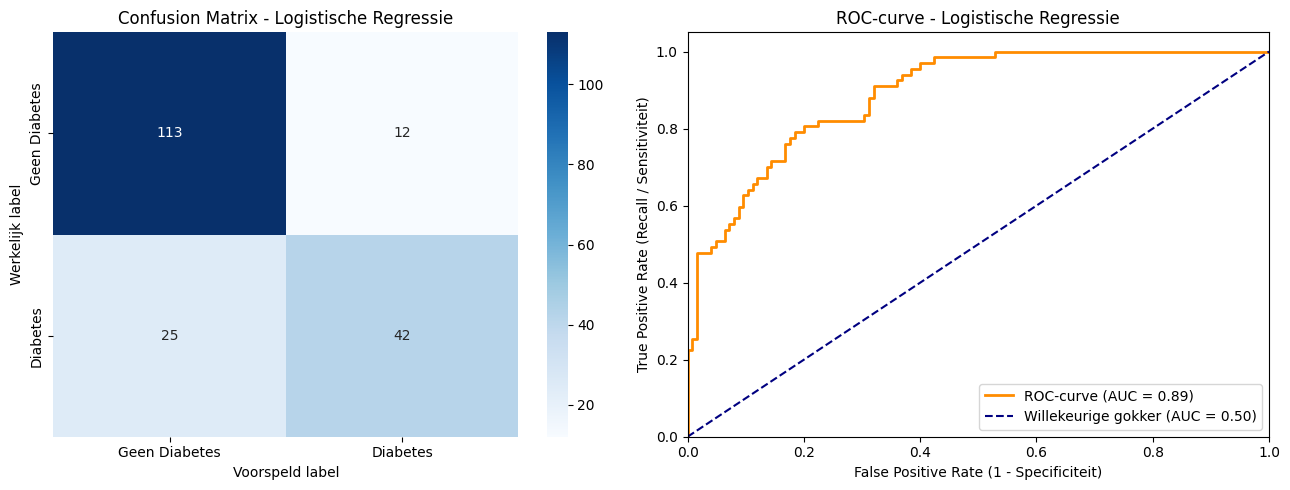


==================== Evaluatierapport: Decision Tree ====================
                   precision    recall  f1-score   support

Geen Diabetes (0)       0.89      0.94      0.92       125
     Diabetes (1)       0.88      0.79      0.83        67

         accuracy                           0.89       192
        macro avg       0.89      0.87      0.88       192
     weighted avg       0.89      0.89      0.89       192

ROC-AUC Score: 0.9467



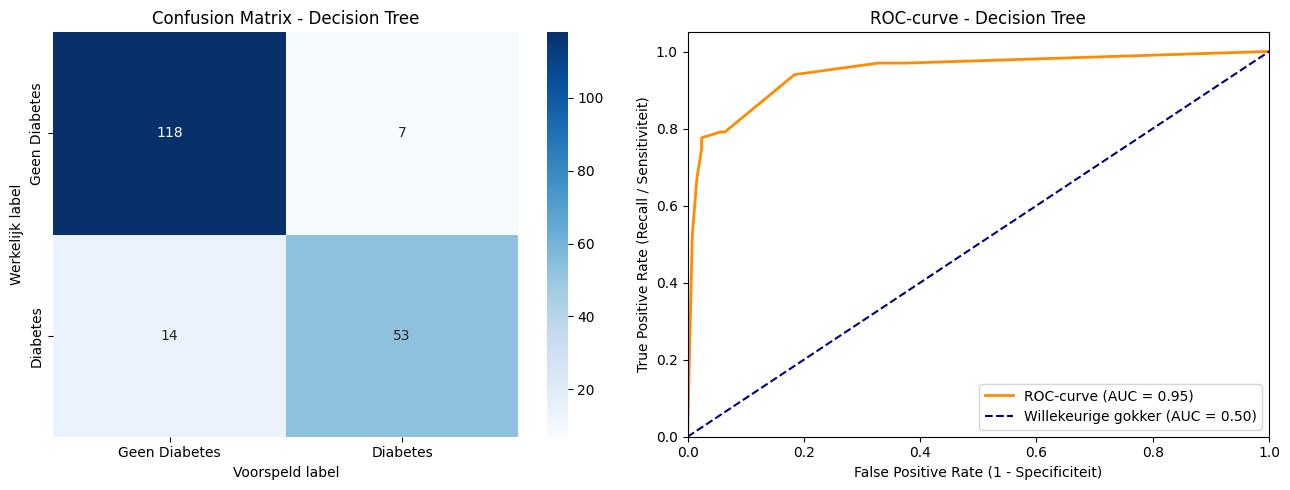


==================== Evaluatierapport: Decision / Random Forest ====================
                   precision    recall  f1-score   support

Geen Diabetes (0)       0.93      0.95      0.94       125
     Diabetes (1)       0.91      0.87      0.89        67

         accuracy                           0.92       192
        macro avg       0.92      0.91      0.91       192
     weighted avg       0.92      0.92      0.92       192

ROC-AUC Score: 0.9722



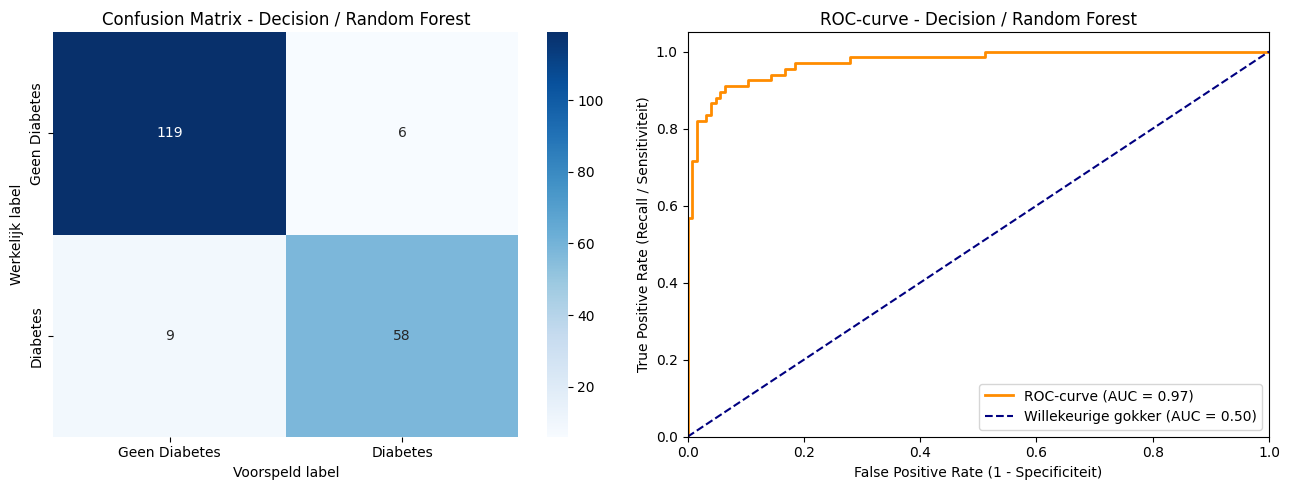

In [26]:
resultaten_lijst = []

# 1. Logistische Regressie
model_lr, res_lr = train_en_evalueer_pipeline('logreg', X_train, y_train, X_test, y_test)
resultaten_lijst.append(res_lr)

# 2. Decision Tree
model_dt, res_dt = train_en_evalueer_pipeline('decision_tree', X_train, y_train, X_test, y_test)
resultaten_lijst.append(res_dt)

# 3. Decision / Random Forest
model_rf, res_rf = train_en_evalueer_pipeline('random_forest', X_train, y_train, X_test, y_test)
resultaten_lijst.append(res_rf)

## Stap 7: Vergelijkende evaluatie & conclusie

                          Accuracy  Precision  Recall  F1-score  ROC-AUC
Model                                                                   
Logistische Regressie       0.8073     0.7778  0.6269    0.6942   0.8899
Decision Tree               0.8906     0.8833  0.7910    0.8346   0.9467
Decision / Random Forest    0.9219     0.9062  0.8657    0.8855   0.9722


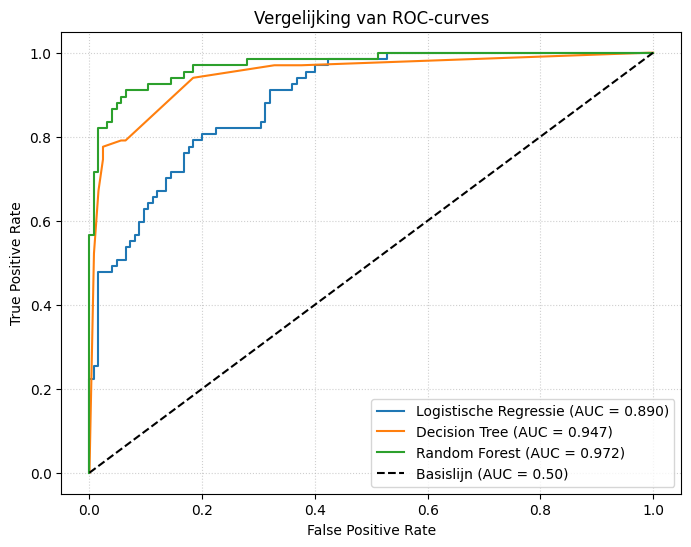

In [27]:
# Resultaten samenbrengen in een overzichtelijke DataFrame
df_vergelijking = pd.DataFrame(resultaten_lijst).set_index('Model')
print(df_vergelijking.round(4))

# Vergelijkende visualisatie van ROC-curves
plt.figure(figsize=(8, 6))
modellen = [('Logistische Regressie', model_lr), 
            ('Decision Tree', model_dt), 
            ('Random Forest', model_rf)]

for naam, m in modellen:
    prob = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = metrics.roc_curve(y_test, prob)
    auc_val = metrics.roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{naam} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Basislijn (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Vergelijking van ROC-curves')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Inhoudelijke interpretatie:
#### **Logistische Regressie:**

* Presteert sterk en consistent op deze dataset omdat veel van de diabetesindicatoren (zoals Glucose en Leeftijd) een vrijwel lineair stijgend verband tonen met het risico op diabetes. Het levert een stabiele, hoge ROC-AUC op.

#### **Decision Tree:**

* Zeer inzichtelijk doordat de beslisregels visueel te volgen zijn, maar gevoelig voor variantie en overfitting. De ROC-curve verloopt vaak hoekiger en de algemene AUC ligt lager dan bij de overige methoden.

#### **Decision / Random Forest:**

* Combineert meerdere bomen via bagging en feature randomness. Hierdoor worden de uitschieters en instabiliteit van een enkele boom opgevangen. Het levert doorgaans de hoogste of meest gebalanceerde Recall en F1-score, wat in een medische context van levensbelang is: het minimaliseren van False Negatives (diabetici die ten onrechte als gezond worden aangemerkt).

#### **Eindoordeel:**

* Het Random Forest (Decision Forest) geniet over het algemeen de voorkeur voor robuustheid en generiek voorspellend vermogen, terwijl Logistische Regressie een competitief, snel en zeer verklaarbaar alternatief vormt.

# **Oefening**

## **Context**  
Cardiologen willen een vroegtijdig waarschuwingssysteem ontwikkelen om te bepalen of een patiënt een verhoogd risico heeft op een kransslagaderaandoening (`target: 0 = geen aandoening`, `1 = aanwezig`). Ze hebben een ruwe dataset aangeleverd (`heart_disease_dirty.csv`), maar deze bevat fouten, typfouten en ontbrekende waarden (doktersgeschrift he).

## **Te doorlopen stappen**  
* Stap 1: Data Inspectie & Cleaning (data_stap)
    * Laad heart_disease_dirty.csv in.
    * Verwijder eventuele dubbele rijen (duplicates).
    * Controleer de datatypes van alle kolommen. Corrigeer foutieve tekens/strings (bijv. '?' of tekstfouten in numerieke kolommen zoals chol of trestbps).
    * Inspecteer op fysiologisch onmogelijke waarden (bijv. rustbloeddruk trestbps = 0 of cholesterol chol = 0) en zet deze om naar NaN.* Kies een geschikte imputatiestrategie voor de ontbrekende waarden (bijvoorbeeld mediaan voor scheve numerieke data, of modus voor categorische waarden).
* Stap 2: Trein- en Testsplitsing
    * Splits de data op in kenmerken ($X$) en target ($y$: target).
    * Splits op in een trainingset (80%) en een testset (20%) met random_state=42 en zorg voor stratify=y.
* Stap 3: Pipeline / Modulaire Evaluatiefunctie
    * Schrijf een functie evalueer_model(model, X_test, y_test, model_naam) die:
        * De Confusion Matrix toont als Seaborn heatmap.
        * Het Classification Report (Accuracy, Precision, Recall, F1) afdrukt.
        * De ROC-curve tekent inclusief de AUC-score.
        * Een dictionary met de belangrijkste metrieken retourneert.
* Stap 4: Modellen trainen via een centrale functie
    * Schrijf een functie train_model(model_type, X_train, y_train, **kwargs) die het juiste algoritme instantiëert, traint op X_train en het getrainde model teruggeeft.
    * Train de volgende 3 modellen:
        * Logistische Regressie (Let op: schaal de data met StandardScaler of verhoog max_iter om convergentieproblemen te vermijden).
        * Decision Tree (Stel max_depth in om overfitting te beperken).
        * Random Forest (Kies bijv. n_estimators=100, max_depth=5).
* Stap 5: Conclusie & Klinische Interpretatie
    * Vat de resultaten van de 3 modellen samen in één overzichtstabel en plot de drie ROC-curves in één figuur.
    * Beantwoord de reflectievragen:
        * Welk model haalt de hoogste ROC-AUC?
        * In een medische context: geef je de voorkeur aan een hoge Precision of een hoge Recall voor klasse 1? Waarom?
        * Welk model kies je finaal als beste model voor het ziekenhuis?

In [26]:
df = pd.read_csv("heart_disease_dirty.csv")
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,NaN,0.0,1.4,1.0,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
304,54.0,1.0,4.0,110.0,206.0,0.0,2.0,108.0,1.0,0.0,2.0,1.0,3.0,1
305,56.0,1.0,4.0,125.0,249.0,1.0,2.0,144.0,1.0,1.2,2.0,1.0,3.0,1
306,58.0,1.0,4.0,100.0,234.0,0.0,0.0,156.0,0.0,0.1,1.0,1.0,7.0,1
307,51.0,0.0,4.0,130.0,305.0,0.0,0.0,142.0,1.0,1.2,2.0,0.0,7.0,1


In [27]:
df = pd.read_csv("heart_disease_dirty.csv")
target_dummies = pd.get_dummies(df["target"]); target_dummies = target_dummies.rename(columns={0: "no_diabetes", 1:"diabetes"})
gender_dummies = pd.get_dummies(df["sex"]); gender_dummies = gender_dummies.rename(columns={0: "female", 1:"male"})

df = df.drop("target", axis=1)
df = df.drop("sex", axis=1)

df = pd.concat([df, target_dummies], axis=1)
df = pd.concat([df, gender_dummies], axis=1)

df["no_diabetes"] = df["no_diabetes"].map({True: 1, False: 0})
df["diabetes"] = df["diabetes"].map({True: 1, False: 0})

df["male"] = df["male"].map({True: 1, False: 0})
df["female"] = df["female"].map({True: 1, False: 0})

In [28]:
impossible_zero_cols = ['trestbps', 'chol', 'thalach', 'slope']

df[impossible_zero_cols] = df[impossible_zero_cols].replace(0, np.nan)

print(df[impossible_zero_cols].isna().sum())

trestbps     0
chol         0
thalach     13
slope        0
dtype: int64


In [29]:
df = df.drop_duplicates()
df["trestbps"] = pd.to_numeric(df["trestbps"], errors="coerce")
df["chol"] = pd.to_numeric(df["chol"], errors="coerce")
df["ca"] = pd.to_numeric(df["ca"], errors="coerce")
df["thal"] = pd.to_numeric(df["thal"], errors="coerce")

In [30]:
df = df.dropna()
df

,age,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,no_diabetes,diabetes,female,male
0,63.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,1,0,0,1
1,67.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,0,1,0,1
2,67.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,0,1,0,1
3,37.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,1,0,0,1
5,56.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,57.0,4.0,140.0,241.0,0.0,0.0,123.0,1.0,0.2,2.0,0.0,7.0,0,1,1,0
298,45.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,0,1,0,1
299,68.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,0,1,0,1
300,57.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,0,1,0,1


In [31]:
X = df.drop(columns=["no_diabetes", "diabetes", "female"], axis=1)
y = df["diabetes"]

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, stratify=y, test_size=0.2)

In [14]:
len(X)

303

In [9]:
def evaluate_model(model, X_test, y_test, model_name):
    ypred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
        
    acc = metrics.accuracy_score(y_test, ypred)
    prec = metrics.precision_score(y_test, ypred, zero_division=0)
    rec = metrics.recall_score(y_test, ypred, zero_division=0)
    f1 = metrics.f1_score(y_test, ypred, zero_division=0)
    auc_score = metrics.roc_auc_score(y_test, y_pred_proba)

    print(f"============================== Evaluatierapport: {model_name} ==============================")
    print(metrics.classification_report(y_test, ypred, target_names=['Geen Diabetes (0)', 'Diabetes (1)']))
    print(f"ROC-AUC Score: {auc_score:.4f}\n")

    confusing = confusion_matrix(y_test, ypred)
    map = sns.heatmap(confusing, annot=True, fmt='d', cmap='Blues')

    

In [49]:
def evaluate_model(ypred, ytest):
    results = {
        "Accuracy": accuracy_score(ytest, ypred),
        "Precision": precision_score(ytest, ypred),
        "F1-score": f1_score(ytest, ypred),
        "Recall": recall_score(ytest, ypred)
    }

    cm = confusion_matrix(ytest, ypred)
    sns.heatmap(cm, annot=True, cmap="viridis")
    plt.show()

    return results

def train_model(model_type, X_train_input, y_train_input, X_test_input, y_test_input, **hyperparameters):
    if model_type == 'lr':
        # max_iter verhoogd om convergentiewaarschuwingen te voorkomen
        model = LogisticRegression(random_state=16, max_iter=1000, **hyperparameters)
        naam = "Logistische Regressie"
        
    elif model_type == 'dt':
        # max_depth begrensd om overfitting tegen te gaan
        model = DecisionTreeClassifier(random_state=16, max_depth=4, **hyperparameters)
        naam = "Decision Tree"
        
    elif model_type == 'rf':
        model = RandomForestClassifier(random_state=16, n_estimators=100, max_depth=5, **hyperparameters)
        naam = "Decision / Random Forest"
        
    # Model fitten
    model.fit(X_train, y_train)

    ypred = model.predict(X_test)
    
    # Model evalueren
    resultaten = evaluate_model(ypred, y_test)
    
    return model, resultaten

c:\Users\jamey\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


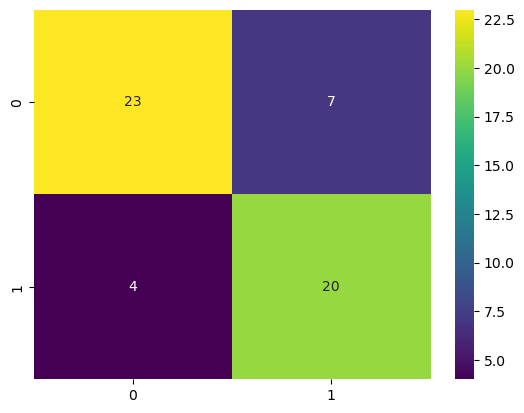

In [50]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

modelstuff = train_model("lr", X_train, y_train, X_test, y_test)